In [1]:
pip install scipy statsmodels



[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chisquare
from scipy.stats import norm
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.proportion import confint_proportions_2indep

In [3]:
cc_df = pd.read_csv('cookie_cats.csv')

In [4]:
cc_df.head()
# control = gate_30 
# test = gate_40

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [5]:
cc_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.2 MB


Data Quality Checks

In [6]:
# one user = one row
cc_df['userid'].is_unique

True

In [7]:
cc_df['retention_1'].value_counts()

retention_1
False    50036
True     40153
Name: count, dtype: int64

In [8]:
cc_df['retention_7'].value_counts()

retention_7
False    73408
True     16781
Name: count, dtype: int64

In [9]:
# Check the number of users in each experiment group
cc_df['version'].value_counts()

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

In [10]:
# Observed group sizes
observed = (
    cc_df["version"]
    .value_counts()
    .reindex(["gate_30", "gate_40"])
)

# Expected group sizes under a 50/50 split
expected = [len(cc_df) / 2, len(cc_df) / 2]

chi2_stat, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

alpha_srm = 0.001

print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < alpha_srm:
    print("SRM detected: check the experiment allocation.")
else:
    print("No SRM detected.")

Chi-square statistic: 6.9024
P-value: 0.0086
No SRM detected.


In [11]:
# Check for duplicated rows
cc_df.duplicated().sum()


np.int64(0)

In [12]:
# Check for negative values in sum_gamerounds
(cc_df['sum_gamerounds'] < 0).sum()

np.int64(0)

In [13]:
# Check whether sum_gamerounds has an integer data type
pd.api.types.is_integer_dtype(cc_df['sum_gamerounds'])

True

In [14]:
# Count users who played zero game rounds
(cc_df["sum_gamerounds"] == 0).sum()

np.int64(3994)

In [15]:
# Check for logical inconsistencies
cc_df[
    (cc_df['sum_gamerounds'] == 0)
    & ((cc_df['retention_1'] == True) | (cc_df['retention_7'] == True))
]

,userid,version,sum_gamerounds,retention_1,retention_7
1000,110479,gate_30,0,False,True
1872,203165,gate_30,0,True,False
2330,257330,gate_30,0,True,False
2803,307703,gate_40,0,True,True
3994,442819,gate_30,0,True,False
...,...,...,...,...,...
86779,9616345,gate_40,0,True,False
87635,9708844,gate_30,0,True,False
87973,9750017,gate_40,0,True,False
88671,9830174,gate_40,0,True,False


A small number of users (111, or approximately 0.12% of the dataset)
were marked as retained despite having zero recorded game rounds.

This may reflect differences between retention and game-round event
definitions or a minor tracking inconsistency. These users were retained
in the primary analysis to avoid post-randomization filtering.

The number of game rounds is strongly right-skewed in both experiment
groups. The median and interquartile ranges appear similar, and no clear
difference between the groups can be identified visually.

Values outside the boxplot whiskers are not necessarily data errors;
they may represent highly active players.

_____________________________________________________________________________________________________________________

## Hypotheses

The primary metric is 7-day player retention.

- **Null hypothesis (H₀):** 7-day retention is equal in the `gate_30`
  and `gate_40` groups.
- **Alternative hypothesis (H₁):** 7-day retention differs between the
  `gate_30` and `gate_40` groups.

A two-sided test is used because moving the gate may either increase or
decrease player retention.

The significance level is set at α = 0.05.

In [16]:
# All users, Returned users, Retention
retention_summary = (
    cc_df.groupby('version')['retention_7']
    .agg(['size', 'sum', 'mean'])
)
print(retention_summary)

          size   sum      mean
version                       
gate_30  44700  8502  0.190201
gate_40  45489  8279  0.182000


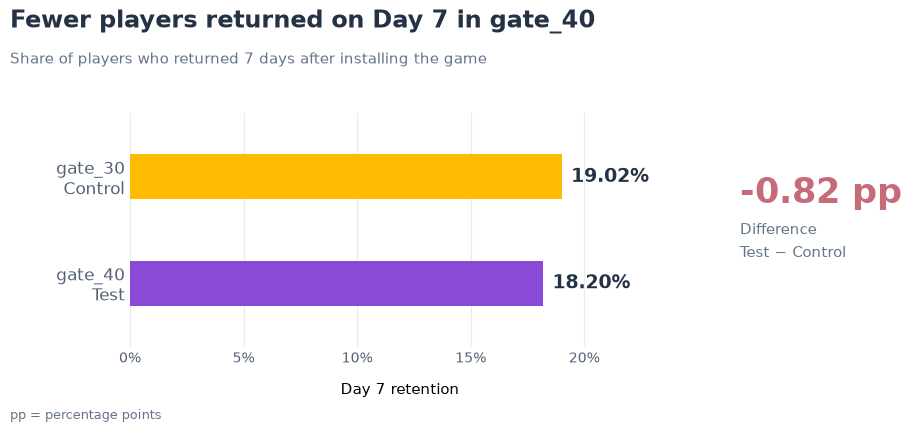

In [17]:
import matplotlib.pyplot as plt

# Day 7 retention
groups = ['gate_30', 'gate_40']
retention_pct = [
    float(retention_summary.loc[group, 'mean']) * 100
    for group in groups
]
difference_pp = retention_pct[1] - retention_pct[0]

# Chart
with plt.style.context('default'):
    fig, ax = plt.subplots(figsize=(10, 4.5))
    fig.subplots_adjust(left=0.18, right=0.72, top=0.72, bottom=0.20)

    colors = ['#FFBB00', '#8B49D7']

    ax.barh(
        [0, 1],
        retention_pct,
        height=0.42,
        color=colors
    )

    # Direct percentage labels
    for position, value in enumerate(retention_pct):
        ax.text(
            value + 0.4, position,
            f'{value:.2f}%',
            va='center',
            fontsize=14,
            fontweight='bold',
            color='#253246'
        )

    ax.set_yticks(
        [0, 1],
        labels=['gate_30\nControl', 'gate_40\nTest'],
        fontsize=12
    )
    ax.set_ylim(1.6, -0.6)
    ax.set_xlim(0, max(retention_pct) * 1.25)

    ax.set_xticks([0, 5, 10, 15, 20])
    ax.set_xticklabels(['0%', '5%', '10%', '15%', '20%'])
    ax.set_xlabel('Day 7 retention', fontsize=11, labelpad=12)

    ax.set_axisbelow(True)
    ax.grid(axis='x', color='#E8ECF1', linewidth=0.8)
    ax.tick_params(axis='both', length=0, colors='#526075')

    for spine in ax.spines.values():
        spine.set_visible(False)

    # Title and subtitle
    fig.text(
        0.06, 0.91,
        'Fewer players returned on Day 7 in gate_40',
        fontsize=17,
        fontweight='bold',
        color='#253246'
    )
    fig.text(
        0.06, 0.83,
        'Share of players who returned 7 days after installing the game',
        fontsize=11,
        color='#65748B'
    )

    # Effect annotation
    fig.text(
        0.79, 0.52,
        f'{difference_pp:+.2f} pp',
        fontsize=25,
        fontweight='bold',
        color='#C76B78'
    )
    fig.text(
        0.79, 0.40,
        'Difference\nTest − Control',
        fontsize=11,
        color='#65748B',
        linespacing=1.5
    )

    fig.text(
        0.06, 0.04,
        'pp = percentage points',
        fontsize=9,
        color='#65748B'
    )

    plt.show()

### Minimum Detectable Effect (MDE)

Since historical data is unavailable, we use the observed Day 7 retention in the control group (`gate_30`), approximately 19% (0.19), as the baseline retention rate. The calculation uses the unrounded value.

We estimate the MDE using the actual sample sizes of both groups, a significance level of 0.05, and 80% statistical power for a two-sided test.

This is a retrospective assessment of the experiment's sensitivity, not a business-defined minimum improvement.

In [18]:
# Baseline retention and actual group sizes
p_baseline = float(retention_summary.loc['gate_30', 'mean'])
n_control = int(retention_summary.loc['gate_30', 'size'])
n_test = int(retention_summary.loc['gate_40', 'size'])

alpha = 0.05
power = 0.80

# Z-values for a two-sided test and the target power
z_alpha = norm.ppf(1 - alpha / 2)
z_power = norm.ppf(power)

# Approximate standard error under the baseline assumption
se_baseline = (
    p_baseline * (1 - p_baseline)
    * (1 / n_control + 1 / n_test)
) ** 0.5

# Approximate minimum detectable effect
mde = (z_alpha + z_power) * se_baseline

print(f'Approximate MDE: {mde * 100:.2f} pp')
print(f'Relative MDE: {mde / p_baseline * 100:.2f}%')

Approximate MDE: 0.73 pp
Relative MDE: 3.85%


Two-Proportion Z-Test for Day 7 Retention

In [19]:
# Test / control: gate_40 − gate_30
group_order = ['gate_40', 'gate_30']

count = retention_summary.loc[group_order, 'sum']
nobs = retention_summary.loc[group_order, 'size']

z_stat, p_value = proportions_ztest(
    count=count,
    nobs=nobs,
    value=0,
    alternative='two-sided'
)

print('Z-statistic:', z_stat)
print('p-value:', p_value)

Z-statistic: -3.164358912748191
p-value: 0.0015542499756143289


### 95% Confidence Interval for the Difference in Day 7 Retention

The difference is calculated as **gate_40 − gate_30** and expressed in **percentage points (pp)**.

In [20]:
# 95% confidence interval: gate_40 − gate_30
ci_low, ci_high = confint_proportions_2indep(
    count1=retention_summary.loc['gate_40', 'sum'],
    nobs1=retention_summary.loc['gate_40', 'size'],
    count2=retention_summary.loc['gate_30', 'sum'],
    nobs2=retention_summary.loc['gate_30', 'size'],
    compare='diff',
    method='wald',
    alpha=0.05
)

p40 = float(retention_summary.loc['gate_40', 'mean'])
p30 = float(retention_summary.loc['gate_30', 'mean'])

difference = p40 - p30

print(f'Difference: {difference * 100:.2f} pp')
print(f'95% CI: [{ci_low * 100:.2f}, {ci_high * 100:.2f}] pp')

Difference: -0.82 pp
95% CI: [-1.33, -0.31] pp


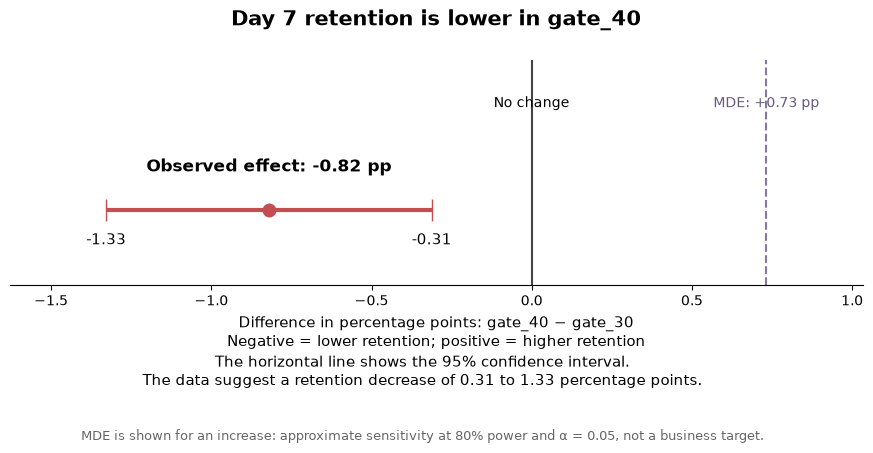

In [21]:
# Convert proportions to percentage points
effect_pp = difference * 100
low_pp = ci_low * 100
high_pp = ci_high * 100
mde_pp = mde * 100

fig, ax = plt.subplots(figsize=(11, 5))
fig.subplots_adjust(bottom=0.35, top=0.80)

# No-change reference
ax.axvline(0, color='#444444', linewidth=1.5)
ax.text(0, 0.48, 'No change', ha='center', fontsize=10)

# MDE in the positive direction
ax.axvline(
    mde_pp, color='#8876A8',
    linestyle='--', linewidth=1.5
)
ax.text(
    mde_pp, 0.48,
    f'MDE: +{mde_pp:.2f} pp',
    ha='center', fontsize=10, color='#695780'
)

# Observed effect and 95% confidence interval
ax.errorbar(
    effect_pp, 0,
    xerr=[[effect_pp - low_pp], [high_pp - effect_pp]],
    fmt='o', color='#C44E52',
    markersize=9, capsize=8, elinewidth=3
)

ax.text(
    effect_pp, 0.18,
    f'Observed effect: {effect_pp:+.2f} pp',
    ha='center', fontsize=12, fontweight='bold'
)

for bound in [low_pp, high_pp]:
    ax.text(
        bound, -0.16, f'{bound:.2f}',
        ha='center', fontsize=11
    )

ax.set_title(
    'Day 7 retention is lower in gate_40',
    fontsize=15, fontweight='bold', pad=25
)
ax.set_xlabel(
    'Difference in percentage points: gate_40 − gate_30\n'
    'Negative = lower retention; positive = higher retention',
    fontsize=11
)

ax.set_yticks([])
ax.set_ylim(-0.35, 0.7)
ax.set_xlim(min(low_pp, 0) - 0.3, max(high_pp, mde_pp) + 0.3)
ax.grid(False)

for side in ['top', 'left', 'right']:
    ax.spines[side].set_visible(False)

fig.text(
    0.5, 0.15,
    'The horizontal line shows the 95% confidence interval.\n'
    f'The data suggest a retention decrease of '
    f'{abs(high_pp):.2f} to {abs(low_pp):.2f} percentage points.',
    ha='center', fontsize=11
)
fig.text(
    0.5, 0.04,
    'MDE is shown for an increase: approximate sensitivity at '
    '80% power and α = 0.05, not a business target.',
    ha='center', fontsize=9, color='#666666'
)

plt.show()

### Day 1 Retention Analysis    

In [22]:
# All users, Returned users, Retention
retention_1_summary = (
    cc_df.groupby('version')['retention_1']
    .agg(['size', 'sum', 'mean'])
)
print(retention_1_summary)

          size    sum      mean
version                        
gate_30  44700  20034  0.448188
gate_40  45489  20119  0.442283


In [23]:
# Baseline retention and actual group sizes
p_baseline = float(retention_1_summary.loc['gate_30', 'mean'])
n_control = int(retention_1_summary.loc['gate_30', 'size'])
n_test = int(retention_1_summary.loc['gate_40', 'size'])

alpha = 0.05
power = 0.80

# Z-values for a two-sided test and the target power
z_alpha = norm.ppf(1 - alpha / 2)
z_power = norm.ppf(power)

# Approximate standard error under the baseline assumption
se_baseline = (
    p_baseline * (1 - p_baseline)
    * (1 / n_control + 1 / n_test)
) ** 0.5

# Approximate minimum detectable effect
mde_1 = (z_alpha + z_power) * se_baseline

print(f'Approximate MDE: {mde_1 * 100:.2f} pp')
print(f'Relative MDE: {mde_1 / p_baseline * 100:.2f}%')

Approximate MDE: 0.93 pp
Relative MDE: 2.07%


In [24]:
# Test / control: gate_40 − gate_30
group_order = ['gate_40', 'gate_30']

count = retention_1_summary.loc[group_order, 'sum']
nobs = retention_1_summary.loc[group_order, 'size']

z_stat_1, p_value_1 = proportions_ztest(
    count=count,
    nobs=nobs,
    value=0,
    alternative='two-sided'
)

print('Z-statistic:', z_stat_1)
print('p-value:', p_value_1)

Z-statistic: -1.7840862247974725
p-value: 0.07440965529691913


In [25]:
# 95% confidence interval: gate_40 − gate_30
ci_low_1, ci_high_1 = confint_proportions_2indep(
    count1=retention_1_summary.loc['gate_40', 'sum'],
    nobs1=retention_1_summary.loc['gate_40', 'size'],
    count2=retention_1_summary.loc['gate_30', 'sum'],
    nobs2=retention_1_summary.loc['gate_30', 'size'],
    compare='diff',
    method='wald',
    alpha=0.05
)

p40_1 = float(retention_1_summary.loc['gate_40', 'mean'])
p30_1 = float(retention_1_summary.loc['gate_30', 'mean'])

difference_1 = p40_1 - p30_1

print(f'Difference: {difference * 100:.2f} pp')
print(f'95% CI: [{ci_low * 100:.2f}, {ci_high * 100:.2f}] pp')

Difference: -0.82 pp
95% CI: [-1.33, -0.31] pp


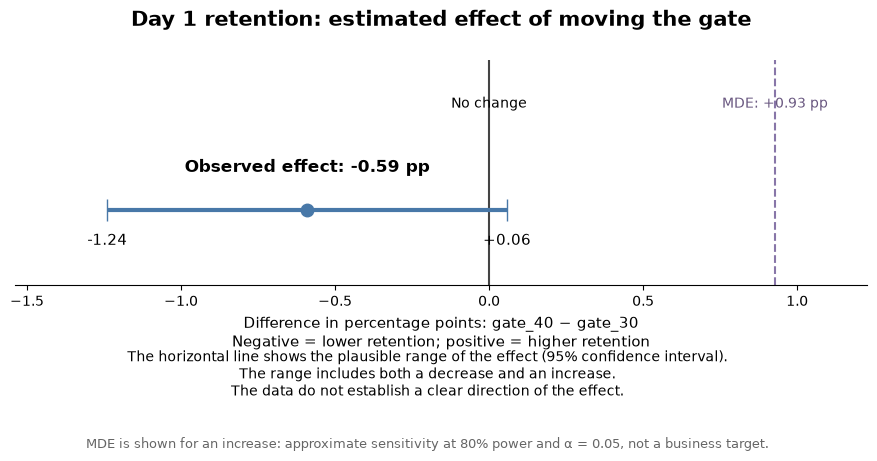

In [26]:
# Day 1: convert proportions to percentage points
effect_pp_1 = difference_1 * 100
low_pp_1 = ci_low_1 * 100
high_pp_1 = ci_high_1 * 100
mde_pp_1 = mde_1 * 100

fig, ax = plt.subplots(figsize=(11, 5))
fig.subplots_adjust(bottom=0.35, top=0.80)

# No-change reference
ax.axvline(0, color='#444444', linewidth=1.5)
ax.text(0, 0.48, 'No change', ha='center', fontsize=10)

# MDE in the positive direction
ax.axvline(
    mde_pp_1,
    color='#8876A8',
    linestyle='--',
    linewidth=1.5
)
ax.text(
    mde_pp_1, 0.48,
    f'MDE: +{mde_pp_1:.2f} pp',
    ha='center', fontsize=10, color='#695780'
)

# Observed effect and 95% confidence interval
ax.errorbar(
    effect_pp_1, 0,
    xerr=[
        [effect_pp_1 - low_pp_1],
        [high_pp_1 - effect_pp_1]
    ],
    fmt='o',
    color='#4878A8',
    markersize=9,
    capsize=8,
    elinewidth=3
)

ax.text(
    effect_pp_1, 0.18,
    f'Observed effect: {effect_pp_1:+.2f} pp',
    ha='center', fontsize=12, fontweight='bold'
)

for bound in [low_pp_1, high_pp_1]:
    ax.text(
        bound, -0.16,
        f'{bound:+.2f}',
        ha='center', fontsize=11
    )

ax.set_title(
    'Day 1 retention: estimated effect of moving the gate',
    fontsize=15, fontweight='bold', pad=25
)
ax.set_xlabel(
    'Difference in percentage points: gate_40 − gate_30\n'
    'Negative = lower retention; positive = higher retention',
    fontsize=11
)

ax.set_yticks([])
ax.set_ylim(-0.35, 0.7)
ax.set_xlim(
    min(low_pp_1, 0) - 0.3,
    max(high_pp_1, mde_pp_1) + 0.3
)
ax.grid(False)

for side in ['top', 'left', 'right']:
    ax.spines[side].set_visible(False)

# Plain-language interpretation
if low_pp_1 <= 0 <= high_pp_1:
    interpretation = (
        'The range includes both a decrease and an increase.\n'
        'The data do not establish a clear direction of the effect.'
    )
elif high_pp_1 < 0:
    interpretation = (
        f'The data suggest a retention decrease of '
        f'{abs(high_pp_1):.2f} to {abs(low_pp_1):.2f} percentage points.'
    )
else:
    interpretation = (
        f'The data suggest a retention increase of '
        f'{low_pp_1:.2f} to {high_pp_1:.2f} percentage points.'
    )

fig.text(
    0.5, 0.13,
    'The horizontal line shows the plausible range of the effect '
    '(95% confidence interval).\n' + interpretation,
    ha='center', fontsize=10
)
fig.text(
    0.5, 0.025,
    'MDE is shown for an increase: approximate sensitivity at '
    '80% power and α = 0.05, not a business target.',
    ha='center', fontsize=9, color='#666666'
)

plt.show()

In [27]:
cc_df['sum_gamerounds'].describe(
    percentiles=[0.50, 0.95, 0.99]
)

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
50%         16.000000
95%        221.000000
99%        493.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

In [28]:
cc_df[(cc_df['sum_gamerounds'] > 2000)]

,userid,version,sum_gamerounds,retention_1,retention_7
6536,725080,gate_40,2015,True,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
36933,4090246,gate_40,2124,True,True
43671,4832608,gate_30,2438,True,True
46344,5133952,gate_30,2251,True,True
48188,5346171,gate_40,2294,True,True
57702,6390605,gate_30,49854,False,True
87007,9640085,gate_30,2156,True,True
88328,9791599,gate_40,2063,True,True


In [29]:
# Identify the extreme observation
cc_df.nlargest(1, 'sum_gamerounds')

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True


In [30]:
# Exclude one extreme observation from the game-round analysis
extreme_index = cc_df['sum_gamerounds'].idxmax()

rounds_df = cc_df.drop(index=extreme_index).copy()

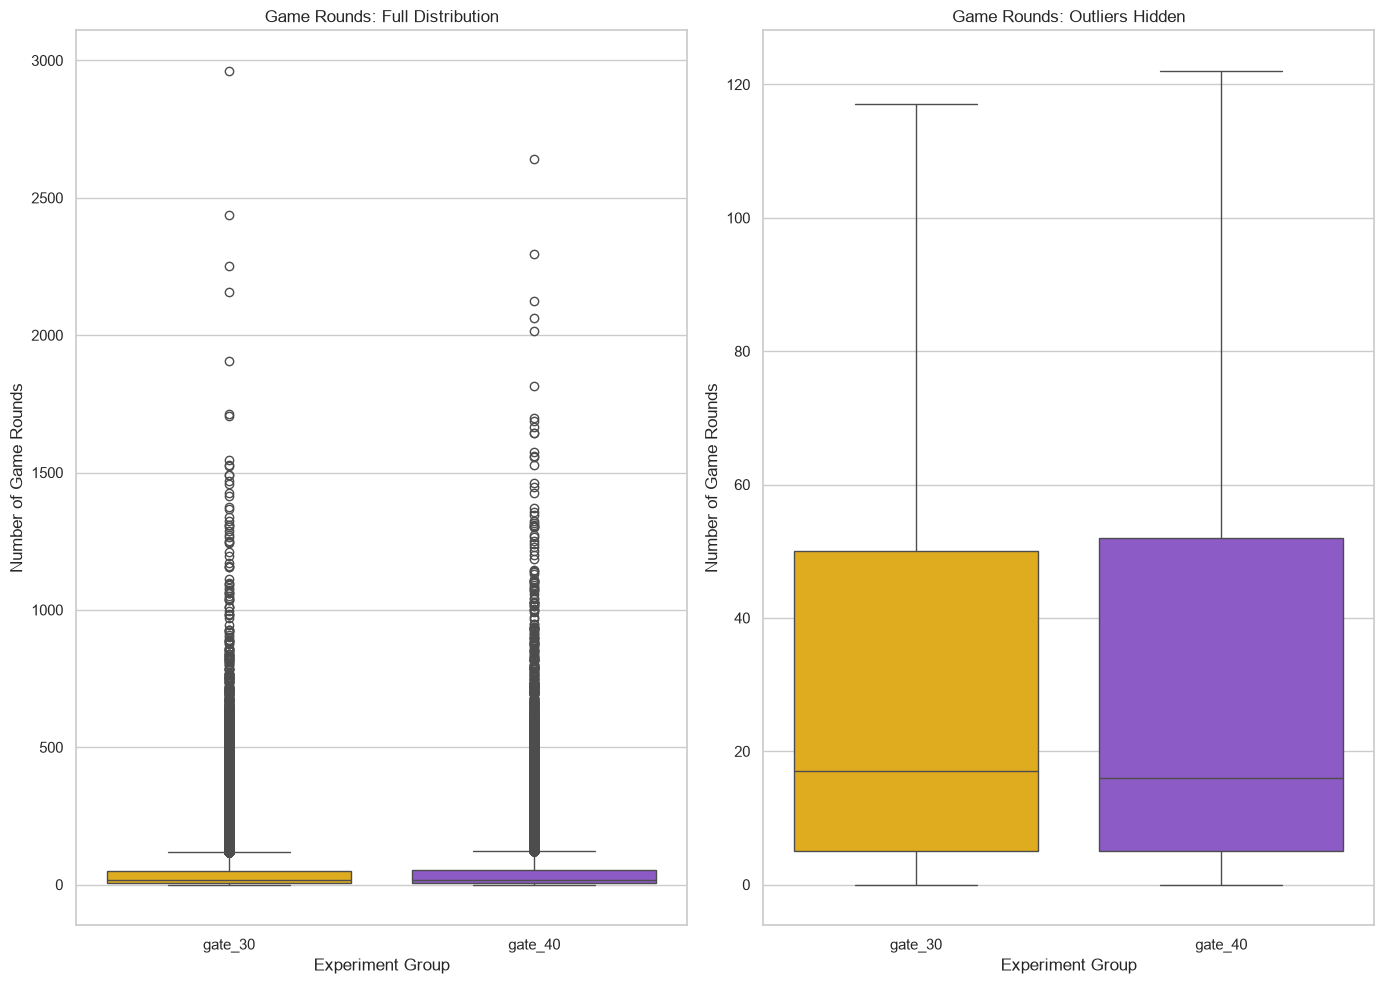

In [31]:
sns.set_theme(style='whitegrid')

group_order = ['gate_30', 'gate_40']

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 10)
)

# Full distribution
sns.boxplot(
    data=rounds_df,
    x='version',
    y='sum_gamerounds',
    order=group_order,
    hue='version',
    palette=["#FFBB00", "#8B49D7"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title('Game Rounds: Full Distribution')
axes[0].set_xlabel('Experiment Group')
axes[0].set_ylabel('Number of Game Rounds')

# Distribution without displaying outlier points
sns.boxplot(
    data=rounds_df,
    x='version',
    y='sum_gamerounds',
    order=group_order,
    hue='version',
    palette=["#FFBB00", "#8B49D7"],
    legend=False,
    showfliers=False,
    ax=axes[1]
)

axes[1].set_title('Game Rounds: Outliers Hidden')
axes[1].set_xlabel('Experiment Group')
axes[1].set_ylabel('Number of Game Rounds')

plt.tight_layout()
plt.show()

In [32]:
rounds_df.groupby('version')['sum_gamerounds'].describe(percentiles=[0.5, 0.75, 0.9])

,count,mean,std,min,50%,75%,90%,max
version,,,,,,,,
gate_30,44699.0,51.342111,102.057598,0.0,17.0,50.0,135.0,2961.0
gate_40,45489.0,51.298776,103.294416,0.0,16.0,52.0,134.0,2640.0


### Game Rounds: Hypothesis Testing

We compare the mean number of game rounds per user between the control group (`gate_30`) and the test group (`gate_40`) using a two-sided Welch’s t-test.

- **H₀:** The mean number of game rounds is equal in both groups (μ₄₀ = μ₃₀).
- **H₁:** The mean number of game rounds differs between the groups (μ₄₀ ≠ μ₃₀).

**Significance level:** α = 0.05.

This exploratory analysis excludes one user with 49,854 game rounds. The retention analyses include this user.

In [33]:
rounds_40 = rounds_df.loc[
    rounds_df['version'] == 'gate_40', 'sum_gamerounds'
]
rounds_30 = rounds_df.loc[
    rounds_df['version'] == 'gate_30', 'sum_gamerounds'
]

t_stat_rounds, p_value_rounds = ttest_ind(
    rounds_40,
    rounds_30,
    equal_var=False,
    alternative='two-sided'
)

print(f'T-statistic: {t_stat_rounds:.4f}')
print(f'p-value: {p_value_rounds:.4f}')
print(f'Mean difference: {rounds_40.mean() - rounds_30.mean():.4f} rounds')

T-statistic: -0.0634
p-value: 0.9495
Mean difference: -0.0433 rounds
